# 04 - Kiểm toán Rò rỉ Dữ liệu, Tiền xử lý Ảnh Điện thoại & Stress Test (A / B / C)

**Dự án:** Chẩn đoán Bệnh trên Lá Cây Nông Nghiệp (`feat/efficientnet-b0-tri`)  
**Mục tiêu:**
1. Kiểm toán mức độ rò rỉ "ảnh anh em xoay/lật" trong bộ dữ liệu Kaggle Augmented (`data/train` vs `data/valid`).
2. Xây dựng bộ tiền xử lý ảnh điện thoại thực tế `MobileLeafPreprocessor` (**Bilateral Filter + LAB-CLAHE trên kênh L + Adaptive Unsharp Mask**) và kiểm chứng trực quan trước/sau.
3. Chạy thí nghiệm đối chứng **4 cấu hình (Mốc A → Mốc B → Đối chứng v2 không Preproc → Mốc C)** trên **6.108 chiếc lá sạch (`0%` rò rỉ)** qua 7 kịch bản nhiễu giống ảnh chụp điện thoại thực tế.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torchvision import transforms

from mobile_preprocessing_tri import (
    MobileLeafPreprocessor,
    DeterministicLightingShiftPIL,
    DeterministicGaussianNoisePIL,
    DeterministicOcclusionPIL,
)

sns.set_theme(style="whitegrid")
data = json.loads(Path("stress_test_comparison_tri.json").read_text(encoding="utf-8"))
v2_meta = json.loads(Path("efficientnet_b0_robust_tri_results.json").read_text(encoding="utf-8"))

print(f"Tổng ảnh valid: {data['unseen_valid_count'] + data['sibling_valid_count']:,}")
print(f"  - Có ảnh anh em xoay/lật trong train: {data['sibling_valid_count']:,} ({data['sibling_leakage_pct']}%)")
print(f"  - Lá mới hoàn toàn (0% rò rỉ):       {data['unseen_valid_count']:,} ({100 - data['sibling_leakage_pct']:.2f}%)")
print(f"EfficientNet-B0 Robust v2 trên full 17.572 valid: Macro-F1 = {v2_meta['final_metrics_with_preproc']['macro_f1']*100:.2f}% | Unseen data/test/: {data['v2_unseen_test_33']}")

Tổng ảnh valid: 17,572
  - Có ảnh anh em xoay/lật trong train: 11,464 (65.24%)
  - Lá mới hoàn toàn (0% rò rỉ):       6,108 (34.76%)
EfficientNet-B0 Robust v2 trên full 17.572 valid: Macro-F1 = 99.91% | Unseen data/test/: 33/33 (100.00%)


### Phân tích Kiểm toán Rò rỉ Dữ liệu (`0%` Leakage Audit)
- Trong tập `data/valid` (17.572 ảnh) của bộ Kaggle *New Plant Diseases Dataset (Augmented)*, có tới **65,24%** (11.464 ảnh) là biến thể xoay/lật của những chiếc lá đã có trong `data/train` (vi phạm nguyên tắc *chia tập trước khi tăng cường dữ liệu* — Chip Huyen Chương 5).
- Vì vậy, toàn bộ Stress Test dưới đây chỉ chấm trên **6.108 chiếc lá hoàn toàn mới (`0%` rò rỉ)** để phản ánh độ bền trung thực nhất.

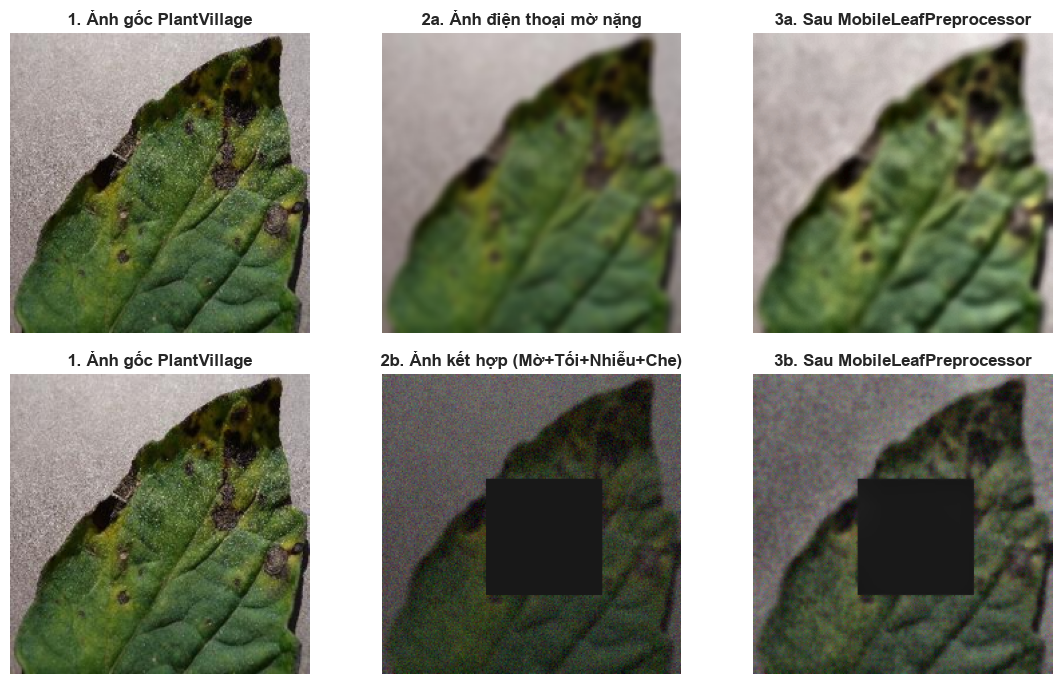

In [2]:
sample = sorted((Path("../data/valid") / "Tomato___Early_blight").glob("*.JPG"))[0]
orig = Image.open(sample).convert("RGB").resize((224, 224))
blur_img = transforms.GaussianBlur(kernel_size=9, sigma=3.0)(orig)
mobile_img = DeterministicOcclusionPIL(0.15)(
    DeterministicGaussianNoisePIL(12.0)(
        DeterministicLightingShiftPIL(0.60, 0.75)(
            transforms.GaussianBlur(kernel_size=5, sigma=1.5)(orig)
        )
    )
)
pre = MobileLeafPreprocessor()
restored_blur = pre(blur_img)
restored_mobile = pre(mobile_img)

fig, axes = plt.subplots(2, 3, figsize=(11.5, 7.0))
items = [
    (orig, "1. Ảnh gốc PlantVillage"),
    (blur_img, "2a. Ảnh điện thoại mờ nặng"),
    (restored_blur, "3a. Sau MobileLeafPreprocessor"),
    (orig, "1. Ảnh gốc PlantVillage"),
    (mobile_img, "2b. Ảnh kết hợp (Mờ+Tối+Nhiễu+Che)"),
    (restored_mobile, "3b. Sau MobileLeafPreprocessor"),
]
for ax, (im, title) in zip(axes.flat, items):
    ax.imshow(im)
    ax.set_title(title, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Cơ chế hoạt động của `MobileLeafPreprocessor` (~2 ms/ảnh)
1. **Chuyển không gian màu RGB → LAB** và chỉ xử lý trên kênh độ sáng **`L`** (giữ nguyên hai kênh màu `A`, `B` để màu xanh/vàng/nâu đặc trưng của bệnh lá không bị lệch sắc).
2. **Lọc nhiễu bảo toàn biên (`Bilateral Filter`)** triệt nhiễu hạt cảm biến điện thoại mà không làm nhòe rìa đốm bệnh.
3. **Cân bằng sáng cục bộ (`CLAHE`, `clipLimit=1.5`)** cứu ảnh bị tối bóng râm hoặc nắng chói.
4. **Làm nét thích ứng (*Adaptive Unsharp Mask*):** Chỉ kích hoạt tăng nét khi phương sai Laplacian `< 120` (ảnh thực sự bị mờ), tránh khuếch đại nhiễu trên ảnh sạch.

,Kịch bản,Mốc A: v1 gốc Acc (F1),Mốc B: v1+Preproc (Skew),v2 Robust (ko Preproc),Mốc C: v2+Preproc ★,Lỗi A → C (trên 6.108)
0,clean,99.90% (99.52%),97.59% (87.52%),99.62% (99.25%),99.85% (99.16%),6 → 9
1,blur_mild,95.46% (83.98%),88.59% (81.93%),98.85% (98.97%),99.67% (96.48%),277 → 20
2,harsh_lighting,98.43% (93.73%),95.04% (85.43%),97.68% (93.93%),99.59% (95.28%),96 → 25
3,occlusion_22pct,98.20% (88.44%),90.73% (81.99%),98.00% (86.19%),99.08% (88.96%),110 → 56
4,blur_heavy,55.09% (50.46%),51.46% (50.36%),95.94% (87.59%),99.35% (93.13%),"2,743 → 40"
5,sensor_noise,54.21% (48.18%),13.02% (10.01%),98.59% (88.63%),99.53% (92.77%),"2,797 → 29"
6,combined_mobile,32.17% (27.27%),5.53% (2.18%),81.61% (67.31%),97.35% (84.75%),"4,143 → 162"


C:\Users\VÕ MINH TRI\AppData\Local\Temp\ipykernel_25264\3589665880.py:42: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
D:\plant-disease-ml\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


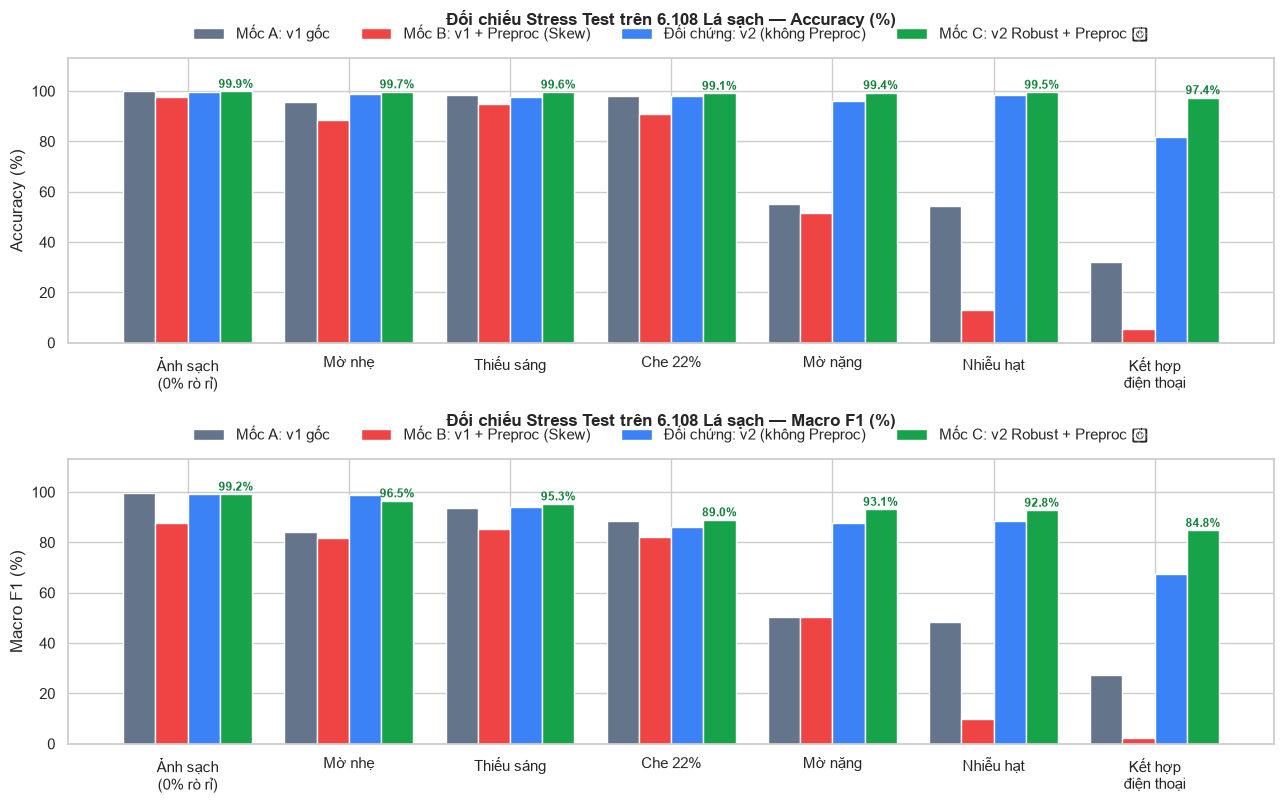

In [3]:
scenarios = ["clean", "blur_mild", "harsh_lighting", "occlusion_22pct", "blur_heavy", "sensor_noise", "combined_mobile"]
rows = []
for s in scenarios:
    a = data["v1_raw"][s]
    b = data["v1_with_preproc"][s]
    vr = data["v2_robust_raw"][s]
    c = data["v2_robust_with_preproc"][s]
    rows.append({
        "Kịch bản": s,
        "Mốc A: v1 gốc Acc (F1)": f"{a['accuracy']*100:.2f}% ({a['macro_f1']*100:.2f}%)",
        "Mốc B: v1+Preproc (Skew)": f"{b['accuracy']*100:.2f}% ({b['macro_f1']*100:.2f}%)",
        "v2 Robust (ko Preproc)": f"{vr['accuracy']*100:.2f}% ({vr['macro_f1']*100:.2f}%)",
        "Mốc C: v2+Preproc ★": f"{c['accuracy']*100:.2f}% ({c['macro_f1']*100:.2f}%)",
        "Lỗi A → C (trên 6.108)": f"{a['errors']:,} → {c['errors']:,}",
    })
display(pd.DataFrame(rows))

labels = ["Ảnh sạch\n(0% rò rỉ)", "Mờ nhẹ", "Thiếu sáng", "Che 22%", "Mờ nặng", "Nhiễu hạt", "Kết hợp\nđiện thoại"]
x = np.arange(len(scenarios))
w = 0.20
fig, axes = plt.subplots(2, 1, figsize=(13, 8.2))
for ax, key, title, ylabel in [
    (axes[0], "accuracy", "Đối chiếu Stress Test trên 6.108 Lá sạch — Accuracy (%)", "Accuracy (%)"),
    (axes[1], "macro_f1", "Đối chiếu Stress Test trên 6.108 Lá sạch — Macro F1 (%)", "Macro F1 (%)"),
]:
    va = [data["v1_raw"][s][key] * 100 for s in scenarios]
    vb = [data["v1_with_preproc"][s][key] * 100 for s in scenarios]
    vr = [data["v2_robust_raw"][s][key] * 100 for s in scenarios]
    vc = [data["v2_robust_with_preproc"][s][key] * 100 for s in scenarios]
    ax.bar(x - 1.5*w, va, width=w, color="#64748b", label="Mốc A: v1 gốc")
    ax.bar(x - 0.5*w, vb, width=w, color="#ef4444", label="Mốc B: v1 + Preproc (Skew)")
    ax.bar(x + 0.5*w, vr, width=w, color="#3b82f6", label="Đối chứng: v2 (không Preproc)")
    bc = ax.bar(x + 1.5*w, vc, width=w, color="#16a34a", label="Mốc C: v2 Robust + Preproc ★")
    for b in bc:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.4, f"{b.get_height():.1f}%", ha="center", fontsize=8.5, fontweight="bold", color="#15803d")
    ax.set_title(title, fontweight="bold", pad=24)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 113)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

### Kết Luận Thực Nghiệm (Ablation Study A / B / C)
1. **Ảnh điện thoại thực tế đánh gục mô hình chỉ học trên ảnh sạch (Mốc A):** `v1` đạt `99,90%` trên ảnh sạch nhưng sập xuống **`55,09%`** (`blur_heavy`), **`54,21%`** (`sensor_noise`) và chỉ còn **`32,17%` Acc / `27,27%` F1** (sai `4.143 / 6.108` ảnh) ở kịch bản `combined_mobile`.
2. **Minh chứng thực tế *Training-Serving Skew* (Mốc B):** Bật tiền xử lý ảnh lúc dự đoán mà không huấn luyện đồng nhất khiến `combined_mobile` sập xuống **`5,53%` Acc / `2,18%` F1**.
3. **Đột phá khi kết hợp Tiền xử lý ảnh + Huấn luyện đồng nhất (Mốc C — `EfficientNet-B0 Robust v2`):**
   - Trên kịch bản khắc nghiệt nhất `combined_mobile`: Accuracy nhảy vọt từ **`32,17%` → `97,35%` (+65,18%)**, Macro-F1 từ **`27,27%` → `84,75%` (+57,48%)**, giảm **`96,1%` số ảnh dự đoán sai** (`4.143` → `162` lỗi)!
   - Trên `blur_heavy`: **`55,09%` → `99,35%` (+44,26%)**; trên `sensor_noise`: **`54,21%` → `99,53%` (+45,32%)**.
   - So với đối chứng `v2` tắt tiền xử lý (`81,61%` trên `combined_mobile`), bản thân `MobileLeafPreprocessor` đóng góp thêm **`+15,74%` Accuracy** và **`+17,44%` Macro-F1**.
   - Đồng thời vẫn giữ vững **`99,91%` Macro-F1** trên full 17.572 ảnh valid và **`33/33 (100%)`** trên tập test độc lập `data/test/`.